# Eixo 2 — Jornada

## Pergunta de investigação

**Quais fatores influenciaram as trajetórias dos participantes até a área em que atuam hoje?**

### Objetivo

Investigar os fatores que influenciaram as trajetórias profissionais dos participantes, identificando os elementos que contribuíram para sua aproximação e inserção na área de tecnologia.

### Variáveis analisadas

- Fatores que influenciaram a trajetória profissional;
- Faixa etária;
- Tempo de atuação na área;
- Área de atuação.

### Estratégia de análise

A investigação será organizada em três dimensões:

1. **Fatores de influência:** identificar quais fatores foram mais assinalados pelos participantes.
2. **Combinação de influências:** observar a quantidade e as combinações de fatores selecionados.
3. **Cruzamentos exploratórios:** investigar possíveis relações entre os fatores assinalados e características do perfil profissional dos participantes.

### Cuidados metodológicos

A pergunta do questionário permite até três seleções por participante. Portanto, as frequências representam o número de participantes que assinalaram cada fator, e não parcelas de um total de respostas exclusivas.

Como a questão permite múltiplas escolhas, a soma das frequências pode ultrapassar o número de respondentes. As análises representam exclusivamente a amostra investigada.

# 01 — Preparação e verificação da base

*Importações, carregamento da fonte original, verificação de integridade e seleção das variáveis.*

In [2]:
# Preparação da base

# Bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Configurações de exibição
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Diretório de execução
diretorio_atual = Path.cwd()

print("Ambiente de análise preparado.")

Ambiente de análise preparado.


In [3]:
# Carregamento da base original

# NOTA SOBRE A VERSÃO DA BASE:
# O arquivo mantém o nome BASELINE_36_RESPOSTAS.csv,
# referente à versão inicial da coleta.
# Seu conteúdo foi atualizado posteriormente e
# corresponde à base consolidada com 54 respostas.

caminho_fonte = (
    diretorio_atual
    / ".."
    / ".."
    / "data"
    / "fonte_original"
    / "Pesquisa — Um Olhar de Quem Está no Campo - BASELINE_36_RESPOSTAS.csv"
).resolve()

if not caminho_fonte.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_fonte}")

df_original = pd.read_csv(caminho_fonte)

print(f"Arquivo: {caminho_fonte.name}")
print(
    f"Dimensões da base: {df_original.shape[0]} linhas × {df_original.shape[1]} colunas"
)

Arquivo: Pesquisa — Um Olhar de Quem Está no Campo - BASELINE_36_RESPOSTAS.csv
Dimensões da base: 54 linhas × 17 colunas


In [4]:
# 01 — Preparação e verificação da base

# 1. Identificação das colunas
colunas_disponiveis = {coluna.strip(): coluna for coluna in df_original.columns}

coluna_fatores = colunas_disponiveis[
    "O que mais influenciou sua trajetória na área em que atua hoje?"
]

coluna_idade = colunas_disponiveis["Faixa Etária"]
coluna_tempo = colunas_disponiveis["Tempo de atuação na Área"]
coluna_area = colunas_disponiveis["Área de Atuação"]

colunas_jornada = [coluna_fatores, coluna_idade, coluna_tempo, coluna_area]

# 2. Seleção das variáveis
df_jornada = df_original[colunas_jornada].copy()

# 3. Verificação das dimensões
print("DIMENSÕES DA BASE")
print(
    f"Base original: {df_original.shape[0]} linhas " f"e {df_original.shape[1]} colunas"
)
print(
    f"Base do Eixo 2: {df_jornada.shape[0]} linhas " f"e {df_jornada.shape[1]} colunas"
)

# 4. Verificação de valores ausentes
print("\nVALORES AUSENTES — BASE DO EIXO 2")

display(df_jornada.isna().sum().to_frame("respostas_ausentes"))

# 5. Verificação de duplicidade
print("\nVERIFICAÇÃO DE DUPLICIDADE")

print(
    "Linhas integralmente idênticas na base original:", df_original.duplicated().sum()
)

print("Linhas idênticas nas quatro variáveis do Eixo 2:", df_jornada.duplicated().sum())

# 6. Verificação da quantidade de fatores selecionados
print("\nQUANTIDADE DE FATORES SELECIONADOS POR PARTICIPANTE")

quantidade_selecoes = (
    df_jornada[coluna_fatores]
    .dropna()
    .apply(lambda resposta: len([item for item in resposta.split(",") if item.strip()]))
    .value_counts()
    .sort_index()
)

display(quantidade_selecoes.to_frame("participantes"))

# 7. Conferência das variáveis selecionadas
print("\nVARIÁVEIS ANALISADAS")

for coluna in colunas_jornada:
    print(f"- {coluna}")

print("\nVERIFICAÇÃO CONCLUÍDA.")

DIMENSÕES DA BASE
Base original: 54 linhas e 17 colunas
Base do Eixo 2: 54 linhas e 4 colunas

VALORES AUSENTES — BASE DO EIXO 2


,respostas_ausentes
O que mais influenciou sua trajetória na área em que atua hoje? \n,0
Faixa Etária,0
Tempo de atuação na Área,0
Área de Atuação,0



VERIFICAÇÃO DE DUPLICIDADE
Linhas integralmente idênticas na base original: 0
Linhas idênticas nas quatro variáveis do Eixo 2: 0

QUANTIDADE DE FATORES SELECIONADOS POR PARTICIPANTE


,participantes
O que mais influenciou sua trajetória na área em que atua hoje? \n,
1,12
2,16
3,26



VARIÁVEIS ANALISADAS
- O que mais influenciou sua trajetória na área em que atua hoje? 

- Faixa Etária
-  Tempo de atuação na Área
-  Área de Atuação

VERIFICAÇÃO CONCLUÍDA.


# 02 — Fatores de influência

Identificação dos fatores mais recorrentes nas trajetórias profissionais dos participantes, considerando a frequência de seleção de cada alternativa.

In [5]:
# Frequência dos fatores de influência

coluna_fatores = colunas_jornada[0]

frequencia_fatores = (
    df_jornada[coluna_fatores]
    .dropna()
    .str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
    .rename_axis("fator")
    .reset_index(name="frequencia")
)

frequencia_fatores["percentual"] = (
    frequencia_fatores["frequencia"] / len(df_jornada) * 100
).round(1)

frequencia_fatores

,fator,frequencia,percentual
0,Autoaprendizado e curiosidade pessoal,38,70.4
1,Formação acadêmica ou cursos,34,63.0
2,Transição de outra carreira,22,40.7
3,Busca por estabilidade ou oportunidade de mercado,13,24.1
4,Indicação ou influência de rede de contatos,7,13.0
5,Acaso ou oportunidade inesperada,7,13.0
6,Familiares da área,1,1.9


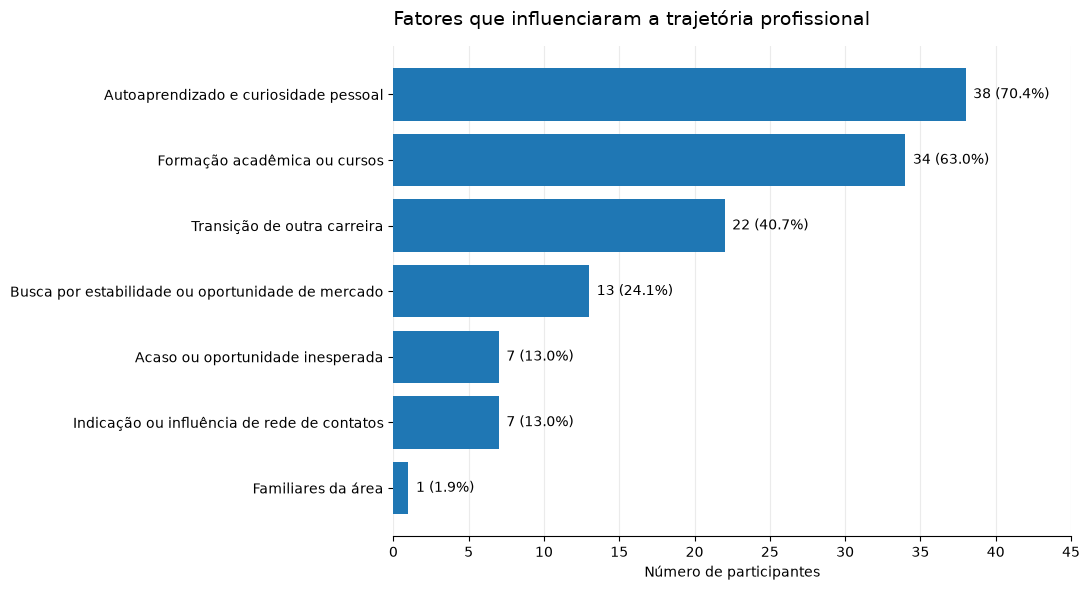

In [6]:
# Visualização — Fatores de influência

dados_grafico = frequencia_fatores.sort_values("frequencia", ascending=True)

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(dados_grafico["fator"], dados_grafico["frequencia"])

for barra, percentual in zip(barras, dados_grafico["percentual"]):
    ax.text(
        barra.get_width() + 0.5,
        barra.get_y() + barra.get_height() / 2,
        f"{int(barra.get_width())} ({percentual:.1f}%)",
        va="center",
    )

ax.set_title(
    "Fatores que influenciaram a trajetória profissional",
    loc="left",
    fontsize=14,
    pad=15,
)

ax.set_xlabel("Número de participantes")
ax.set_ylabel("")

ax.set_xlim(0, 45)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Leitura analítica

O autoaprendizado e a curiosidade pessoal aparecem como o fator mais assinalado, mencionado por 70,4% dos participantes (38). Em seguida, estão a formação acadêmica ou cursos, com 63,0% (34), e a transição de outra carreira, com 40,7% (22).

A busca por estabilidade ou oportunidade de mercado foi indicada por 24,1% dos participantes (13). Indicação ou influência da rede de contatos e acaso ou oportunidade inesperada aparecem com 13,0% cada (7). Familiares da área tiveram apenas uma indicação (1,9%).

Os resultados evidenciam a presença expressiva do aprendizado autônomo e da formação estruturada nas trajetórias investigadas. A transição de carreira também se destaca, indicando que a entrada na tecnologia não ocorre exclusivamente por percursos formativos tradicionais.

# 03 — Combinação de influências

Análise da quantidade de fatores selecionados por participante e identificação das combinações mais recorrentes, considerando a possibilidade de múltiplas escolhas na pergunta.

In [7]:
# Quantidade de fatores selecionados por participante

quantidade_fatores = (
    df_jornada[coluna_fatores]
    .fillna("")
    .apply(
        lambda resposta: len([fator for fator in resposta.split(",") if fator.strip()])
    )
)

distribuicao_selecoes = (
    quantidade_fatores.value_counts()
    .sort_index()
    .rename_axis("quantidade_fatores")
    .reset_index(name="participantes")
)

distribuicao_selecoes["percentual"] = (
    distribuicao_selecoes["participantes"] / len(df_jornada) * 100
).round(1)

distribuicao_selecoes

,quantidade_fatores,participantes,percentual
0,1,12,22.2
1,2,16,29.6
2,3,26,48.1


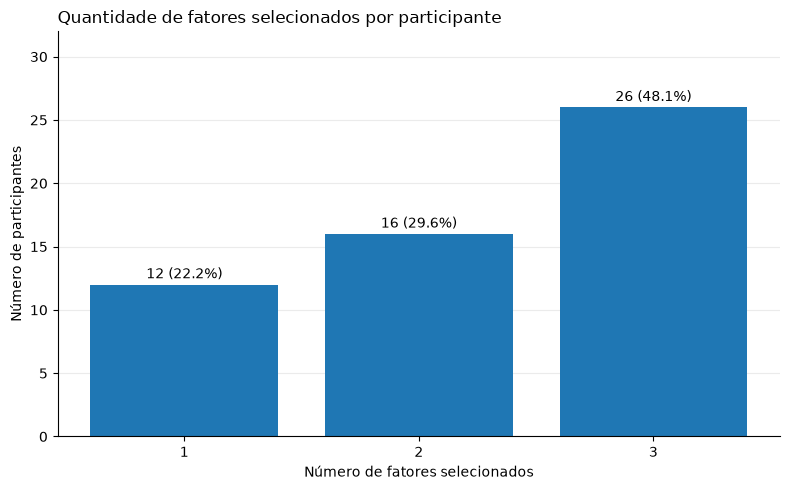

In [8]:
# Visualização — Quantidade de fatores selecionados

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    distribuicao_selecoes["quantidade_fatores"].astype(str),
    distribuicao_selecoes["participantes"],
)

for barra, percentual in zip(barras, distribuicao_selecoes["percentual"]):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.5,
        f"{int(barra.get_height())} ({percentual:.1f}%)",
        ha="center",
    )

ax.set_title("Quantidade de fatores selecionados por participante", loc="left")
ax.set_xlabel("Número de fatores selecionados")
ax.set_ylabel("Número de participantes")
ax.set_ylim(0, 32)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [9]:
# Cálculo e exibição das 10 combinações mais frequentes

# Separação e padronização dos fatores selecionados por participante
combinacoes_respostas = (
    df_jornada[coluna_fatores]
    .fillna("")
    .apply(
        lambda resposta: tuple(
            sorted(fator.strip() for fator in resposta.split(",") if fator.strip())
        )
    )
)

# Remoção de respostas vazias
combinacoes_respostas = combinacoes_respostas[combinacoes_respostas.apply(len) > 0]

# Contagem das combinações
combinacoes_exibicao = (
    combinacoes_respostas.value_counts()
    .rename_axis("fatores")
    .reset_index(name="participantes")
)

# Organização e apresentação dos fatores
combinacoes_exibicao["combinacao"] = combinacoes_exibicao["fatores"].apply(
    lambda fatores: " + ".join(fatores)
)

# Cálculo do percentual sobre o total de participantes
combinacoes_exibicao["percentual"] = (
    combinacoes_exibicao["participantes"] / len(df_jornada) * 100
).round(1)

# Ordenação das combinações mais frequentes
combinacoes_exibicao = combinacoes_exibicao.sort_values(
    ["participantes", "combinacao"], ascending=[False, True]
).reset_index(drop=True)

# Exibição das 10 combinações mais frequentes
for _, linha in combinacoes_exibicao.head(10).iterrows():
    print(
        f"{linha['participantes']} participantes "
        f"({linha['percentual']:.1f}%): "
        f"{linha['combinacao']}"
    )

6 participantes (11.1%): Autoaprendizado e curiosidade pessoal + Busca por estabilidade ou oportunidade de mercado + Transição de outra carreira
6 participantes (11.1%): Autoaprendizado e curiosidade pessoal + Formação acadêmica ou cursos
6 participantes (11.1%): Autoaprendizado e curiosidade pessoal + Formação acadêmica ou cursos + Transição de outra carreira
4 participantes (7.4%): Acaso ou oportunidade inesperada + Autoaprendizado e curiosidade pessoal + Formação acadêmica ou cursos
4 participantes (7.4%): Autoaprendizado e curiosidade pessoal + Busca por estabilidade ou oportunidade de mercado + Formação acadêmica ou cursos
4 participantes (7.4%): Autoaprendizado e curiosidade pessoal + Formação acadêmica ou cursos + Indicação ou influência de rede de contatos
4 participantes (7.4%): Formação acadêmica ou cursos + Transição de outra carreira
4 participantes (7.4%): Transição de outra carreira
3 participantes (5.6%): Formação acadêmica ou cursos
2 participantes (3.7%): Acaso ou opor

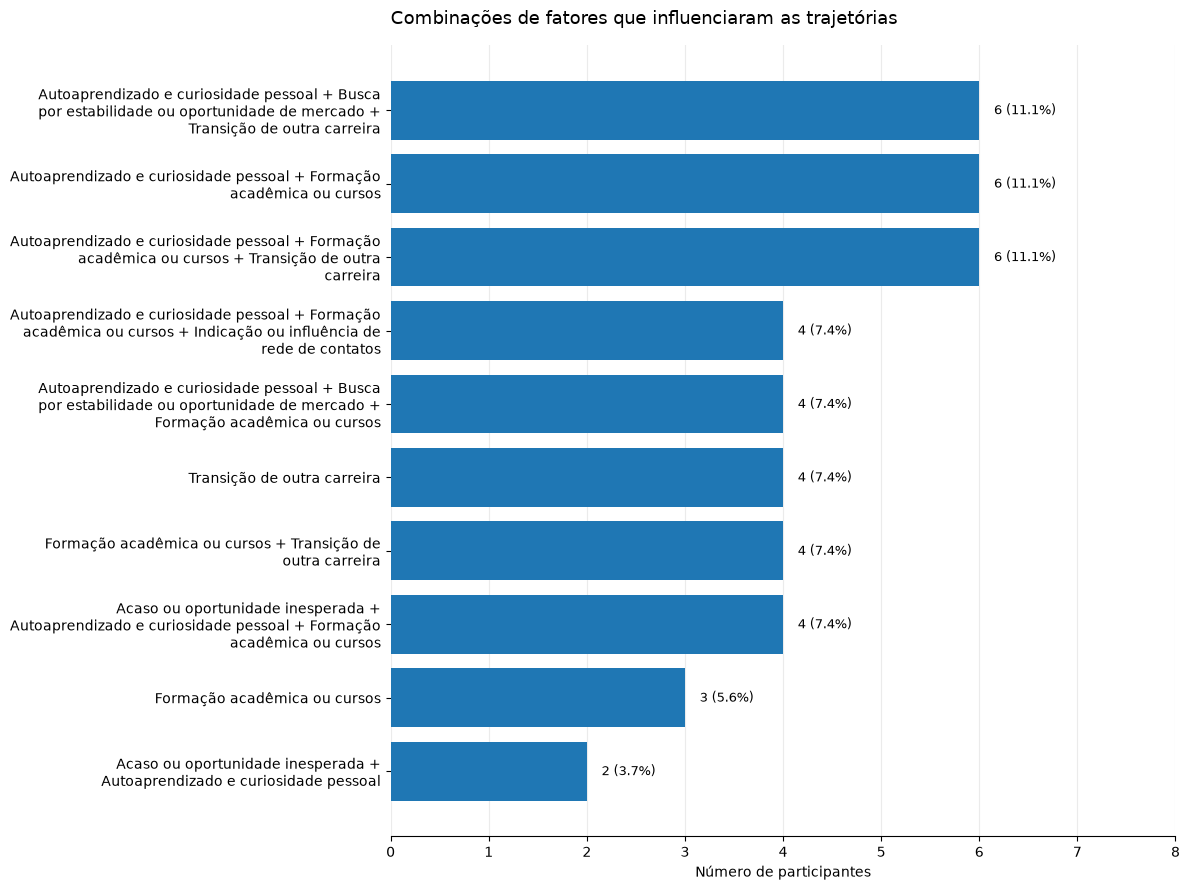

In [10]:
# Visualização — Combinações mais frequentes

from textwrap import fill

dados_combinacoes = combinacoes_exibicao.head(10).copy()

dados_combinacoes["rotulo"] = dados_combinacoes["combinacao"].apply(
    lambda texto: fill(texto, width=48)
)

dados_combinacoes = dados_combinacoes.sort_values("participantes", ascending=True)

fig, ax = plt.subplots(figsize=(12, 9))

barras = ax.barh(dados_combinacoes["rotulo"], dados_combinacoes["participantes"])

for barra, percentual in zip(barras, dados_combinacoes["percentual"]):
    ax.text(
        barra.get_width() + 0.15,
        barra.get_y() + barra.get_height() / 2,
        f"{int(barra.get_width())} ({percentual:.1f}%)",
        va="center",
        fontsize=9,
    )

ax.set_title(
    "Combinações de fatores que influenciaram as trajetórias",
    loc="left",
    fontsize=13,
    pad=15,
)

ax.set_xlabel("Número de participantes")
ax.set_ylabel("")

ax.set_xlim(0, 8)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Leitura analítica

A distribuição das escolhas mostra que 48,1% dos participantes selecionaram os três fatores permitidos pelo questionário. Outros 29,6% escolheram dois fatores e 22,2% indicaram apenas um, evidenciando a presença de múltiplas influências nas trajetórias investigadas.

Na análise das combinações, três agrupamentos aparecem empatados como os mais frequentes, cada um mencionado por 6 participantes (11,1%). Entre eles, estão combinações que articulam autoaprendizado, formação acadêmica ou cursos, transição de carreira e busca por oportunidades de mercado.

O autoaprendizado e a curiosidade pessoal aparecem recorrentemente entre as combinações mais frequentes, assim como a formação acadêmica. A transição de outra carreira também integra diferentes agrupamentos.

A diversidade de combinações e a ausência de um agrupamento predominante indicam que as trajetórias profissionais investigadas são influenciadas por diferentes articulações de fatores, não sendo possível associar a entrada na tecnologia a um percurso único.

# 04 — Cruzamentos exploratórios

Investigação de possíveis relações entre os fatores que influenciaram as trajetórias profissionais e características dos participantes, considerando faixa etária, tempo de atuação e área profissional.

In [11]:
# Cruzamento — Fatores de influência × Faixa etária

df_fatores_idade = df_jornada[[coluna_fatores, "Faixa Etária"]].copy()

df_fatores_idade["fator"] = df_fatores_idade[coluna_fatores].str.split(",")

df_fatores_idade = df_fatores_idade.explode("fator")

df_fatores_idade["fator"] = df_fatores_idade["fator"].str.strip()

df_fatores_idade = df_fatores_idade.dropna(subset=["fator", "Faixa Etária"])

# Frequência por faixa etária

cruzamento_idade = pd.crosstab(
    df_fatores_idade["Faixa Etária"], df_fatores_idade["fator"]
)

cruzamento_idade

fator,Acaso ou oportunidade inesperada,Autoaprendizado e curiosidade pessoal,Busca por estabilidade ou oportunidade de mercado,Familiares da área,Formação acadêmica ou cursos,Indicação ou influência de rede de contatos,Transição de outra carreira
Faixa Etária,,,,,,,
25–34,1,6,2,0,6,2,4
35–44,2,6,4,0,7,1,6
45–54,2,11,5,0,7,1,7
55 ou mais,1,6,0,0,5,1,4
Até 24,1,8,2,1,8,2,1
Prefiro não informar,0,1,0,0,1,0,0


In [12]:
# Distribuição dos fatores dentro de cada faixa etária

distribuicao_fatores_idade = (
    pd.crosstab(
        df_fatores_idade["Faixa Etária"], df_fatores_idade["fator"], normalize="index"
    )
    * 100
).round(1)

distribuicao_fatores_idade

fator,Acaso ou oportunidade inesperada,Autoaprendizado e curiosidade pessoal,Busca por estabilidade ou oportunidade de mercado,Familiares da área,Formação acadêmica ou cursos,Indicação ou influência de rede de contatos,Transição de outra carreira
Faixa Etária,,,,,,,
25–34,4.8,28.6,9.5,0.0,28.6,9.5,19.0
35–44,7.7,23.1,15.4,0.0,26.9,3.8,23.1
45–54,6.1,33.3,15.2,0.0,21.2,3.0,21.2
55 ou mais,5.9,35.3,0.0,0.0,29.4,5.9,23.5
Até 24,4.3,34.8,8.7,4.3,34.8,8.7,4.3
Prefiro não informar,0.0,50.0,0.0,0.0,50.0,0.0,0.0


In [13]:
# Percentual de participantes por faixa etária

total_por_faixa = (
    df_jornada["Faixa Etária"].value_counts().reindex(cruzamento_idade.index)
)

percentual_idade = cruzamento_idade.div(total_por_faixa, axis=0).mul(100).round(1)

percentual_idade

fator,Acaso ou oportunidade inesperada,Autoaprendizado e curiosidade pessoal,Busca por estabilidade ou oportunidade de mercado,Familiares da área,Formação acadêmica ou cursos,Indicação ou influência de rede de contatos,Transição de outra carreira
Faixa Etária,,,,,,,
25–34,11.1,66.7,22.2,0.0,66.7,22.2,44.4
35–44,14.3,42.9,28.6,0.0,50.0,7.1,42.9
45–54,14.3,78.6,35.7,0.0,50.0,7.1,50.0
55 ou mais,14.3,85.7,0.0,0.0,71.4,14.3,57.1
Até 24,11.1,88.9,22.2,11.1,88.9,22.2,11.1
Prefiro não informar,0.0,100.0,0.0,0.0,100.0,0.0,0.0


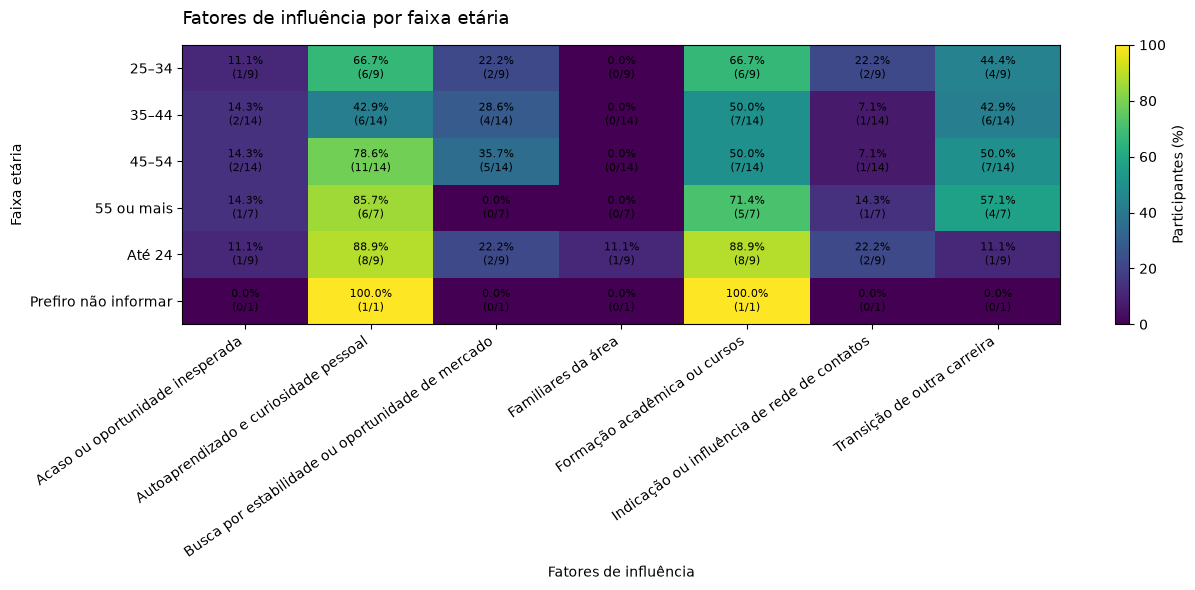

In [14]:
# Visualização — Fatores de influência por faixa etária

# Preserva os rótulos originais da tabela
percentual_idade_grafico = percentual_idade.copy()

# Contagem de participantes que assinalaram cada fator
frequencia_idade_grafico = cruzamento_idade.reindex(
    index=percentual_idade_grafico.index,
    columns=percentual_idade_grafico.columns,
    fill_value=0,
)

# Total de participantes em cada faixa etária
total_idade_grafico = total_por_faixa.reindex(percentual_idade_grafico.index)

fig, ax = plt.subplots(figsize=(13, 6))

imagem = ax.imshow(percentual_idade_grafico, aspect="auto", vmin=0, vmax=100)

# Rótulos dos eixos
ax.set_xticks(range(len(percentual_idade_grafico.columns)))
ax.set_xticklabels(percentual_idade_grafico.columns, rotation=35, ha="right")

ax.set_yticks(range(len(percentual_idade_grafico.index)))
ax.set_yticklabels(percentual_idade_grafico.index)

# Percentual acompanhado da quantidade de participantes
for i in range(len(percentual_idade_grafico.index)):
    for j in range(len(percentual_idade_grafico.columns)):

        percentual = percentual_idade_grafico.iloc[i, j]
        quantidade = frequencia_idade_grafico.iloc[i, j]
        total = total_idade_grafico.iloc[i]

        ax.text(
            j,
            i,
            f"{percentual:.1f}%\n({int(quantidade)}/{int(total)})",
            ha="center",
            va="center",
            fontsize=8,
        )

# Título e identificação dos eixos
ax.set_title("Fatores de influência por faixa etária", loc="left", fontsize=13, pad=15)

ax.set_xlabel("Fatores de influência")
ax.set_ylabel("Faixa etária")

fig.colorbar(imagem, ax=ax, label="Participantes (%)")

plt.tight_layout()
plt.show()

### Leitura analítica

O autoaprendizado e a curiosidade pessoal aparecem em todas as faixas etárias, com destaque entre os participantes de até 24 anos (88,9%) e aqueles com 55 anos ou mais (85,7%). A formação acadêmica ou cursos também apresenta percentuais elevados, alcançando 88,9% no grupo de até 24 anos e 71,4% entre os participantes com 55 anos ou mais.

A transição de outra carreira apresenta maior participação nas faixas de 55 anos ou mais (57,1%) e de 45 a 54 anos (50%). Entre os participantes de até 24 anos, esse fator foi assinalado por 11,1%.

Os resultados mostram que o aprendizado autônomo e a formação estruturada são influências presentes em diferentes gerações. Também apontam diferenças na participação da transição de carreira entre os grupos etários.

As proporções devem ser interpretadas considerando o tamanho reduzido de algumas faixas etárias, especialmente a de 55 anos ou mais. A categoria "Prefiro não informar", composta por apenas um participante, não permite estabelecer comparações.

In [15]:
# Cruzamento — Fatores de influência × Tempo de atuação

coluna_tempo = " Tempo de atuação na Área"

df_fatores_tempo = df_jornada[[coluna_fatores, coluna_tempo]].copy()

df_fatores_tempo["fator"] = df_fatores_tempo[coluna_fatores].str.split(",")

df_fatores_tempo = df_fatores_tempo.explode("fator")

df_fatores_tempo["fator"] = df_fatores_tempo["fator"].str.strip()

df_fatores_tempo = df_fatores_tempo.dropna(subset=["fator", coluna_tempo])

cruzamento_tempo = pd.crosstab(
    df_fatores_tempo[coluna_tempo], df_fatores_tempo["fator"]
)

cruzamento_tempo

fator,Acaso ou oportunidade inesperada,Autoaprendizado e curiosidade pessoal,Busca por estabilidade ou oportunidade de mercado,Familiares da área,Formação acadêmica ou cursos,Indicação ou influência de rede de contatos,Transição de outra carreira
Tempo de atuação na Área,,,,,,,
1–3 anos,1,13,6,0,8,2,8
4–7 anos,1,4,1,1,6,1,4
8–15 anos,3,6,3,0,6,1,1
Mais de 15 anos,2,10,2,0,8,2,3
Menos de 1 ano,0,5,1,0,6,1,6


In [16]:
# Percentual de participantes por tempo de atuação

total_por_tempo = (
    df_jornada[coluna_tempo].value_counts().reindex(cruzamento_tempo.index)
)

percentual_tempo = cruzamento_tempo.div(total_por_tempo, axis=0).mul(100).round(1)

percentual_tempo

fator,Acaso ou oportunidade inesperada,Autoaprendizado e curiosidade pessoal,Busca por estabilidade ou oportunidade de mercado,Familiares da área,Formação acadêmica ou cursos,Indicação ou influência de rede de contatos,Transição de outra carreira
Tempo de atuação na Área,,,,,,,
1–3 anos,6.7,86.7,40.0,0.0,53.3,13.3,53.3
4–7 anos,9.1,36.4,9.1,9.1,54.5,9.1,36.4
8–15 anos,33.3,66.7,33.3,0.0,66.7,11.1,11.1
Mais de 15 anos,18.2,90.9,18.2,0.0,72.7,18.2,27.3
Menos de 1 ano,0.0,62.5,12.5,0.0,75.0,12.5,75.0


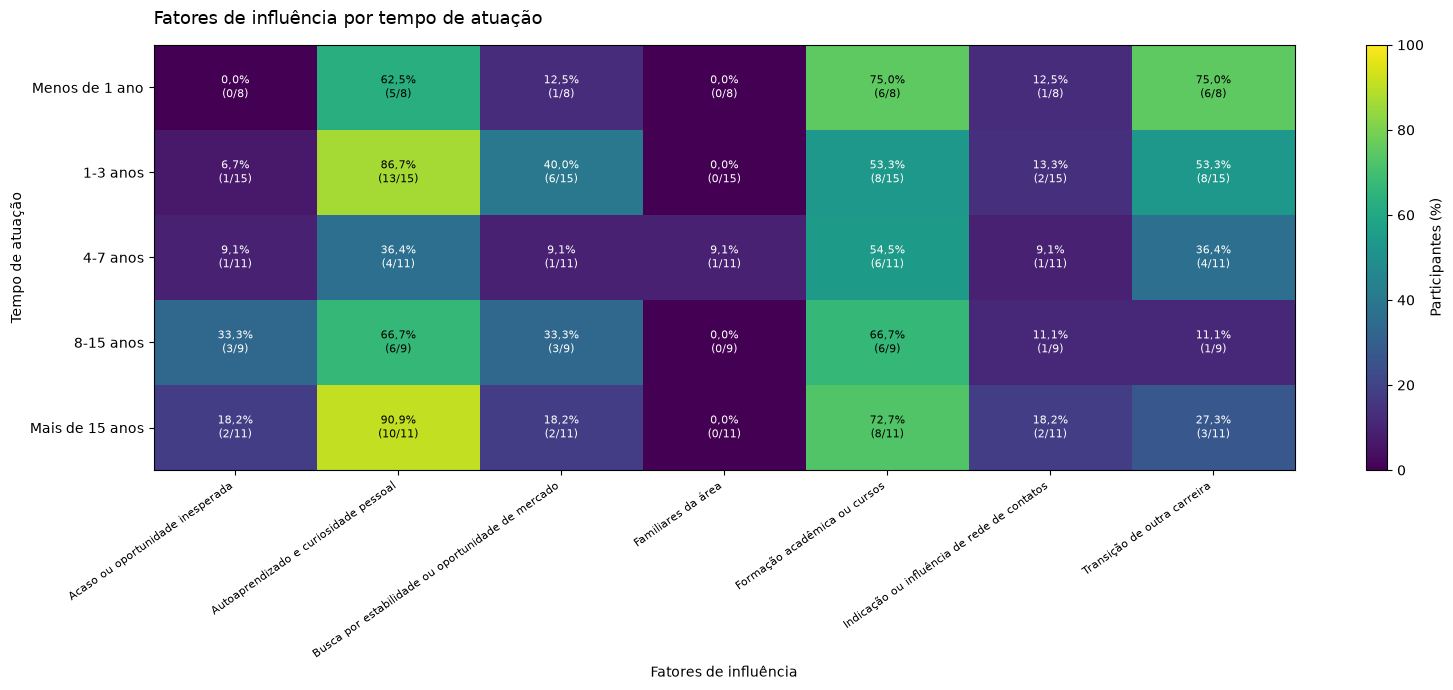

In [17]:
# Visualização — Fatores de influência por tempo de atuação
# Percentual + quantidade de participantes (n/N)

import matplotlib.pyplot as plt
import pandas as pd

# 1. Ordem das categorias
ordem_tempo = ["Menos de 1 ano", "1-3 anos", "4-7 anos", "8-15 anos", "Mais de 15 anos"]

ordem_fatores = [
    "Acaso ou oportunidade inesperada",
    "Autoaprendizado e curiosidade pessoal",
    "Busca por estabilidade ou oportunidade de mercado",
    "Familiares da área",
    "Formação acadêmica ou cursos",
    "Indicação ou influência de rede de contatos",
    "Transição de outra carreira",
]

# 2. Preparação da base
dados = df_jornada[[coluna_tempo, coluna_fatores]].copy()

dados[coluna_tempo] = (
    dados[coluna_tempo]
    .astype(str)
    .str.strip()
    .str.replace(r"[\u2010-\u2015]", "-", regex=True)
)

# 3. Separação dos fatores selecionados
dados[coluna_fatores] = dados[coluna_fatores].fillna("").str.split(",")

dados = dados.explode(coluna_fatores)

dados[coluna_fatores] = dados[coluna_fatores].str.strip()

dados = dados[dados[coluna_fatores] != ""]

# 4. Preparação das matrizes
contagens = pd.DataFrame(0, index=ordem_tempo, columns=ordem_fatores)

totais = dados[[coluna_tempo]].drop_duplicates().set_index(coluna_tempo)

# O denominador vem diretamente da base original
base_tempo = df_jornada[coluna_tempo].copy()

base_tempo = (
    base_tempo.astype(str).str.strip().str.replace(r"[\u2010-\u2015]", "-", regex=True)
)

totais = base_tempo.value_counts().reindex(ordem_tempo, fill_value=0)

# 5. Contagem de participantes por faixa e fator
for faixa in ordem_tempo:

    grupo = dados[dados[coluna_tempo] == faixa]

    for fator in ordem_fatores:

        contagens.loc[faixa, fator] = (grupo[coluna_fatores] == fator).sum()

# 6. Cálculo dos percentuais
percentuais = contagens.div(totais, axis=0) * 100

# 7. Visualização
fig, ax = plt.subplots(figsize=(16, 7))

imagem = ax.imshow(percentuais, cmap="viridis", aspect="auto", vmin=0, vmax=100)

# 8. Rótulos com percentual e quantidade
for i, faixa in enumerate(ordem_tempo):
    for j, fator in enumerate(ordem_fatores):

        percentual = percentuais.loc[faixa, fator]
        quantidade = contagens.loc[faixa, fator]
        total = totais.loc[faixa]

        rotulo = (f"{percentual:.1f}%\n({quantidade}/{total})").replace(".", ",")

        cor_texto = "white" if percentual < 55 else "black"

        ax.text(j, i, rotulo, ha="center", va="center", color=cor_texto, fontsize=8)

# 9. Títulos e eixos
ax.set_title(
    "Fatores de influência por tempo de atuação", loc="left", fontsize=13, pad=15
)

ax.set_xticks(range(len(ordem_fatores)))
ax.set_xticklabels(ordem_fatores, rotation=35, ha="right", fontsize=8)

ax.set_yticks(range(len(ordem_tempo)))
ax.set_yticklabels(ordem_tempo)

ax.set_xlabel("Fatores de influência")
ax.set_ylabel("Tempo de atuação")

barra = fig.colorbar(imagem, ax=ax)
barra.set_label("Participantes (%)")

plt.tight_layout()
plt.show()

### Leitura analítica

O autoaprendizado e a curiosidade pessoal aparecem como influências expressivas em todas as faixas de tempo de atuação. O percentual varia de 62,5% entre participantes com menos de um ano na área a 90,9% entre aqueles com mais de 15 anos.

A formação acadêmica ou cursos também apresenta presença relevante em todos os grupos, com percentuais entre 53,3% e 75%.

A transição de outra carreira apresenta maior participação entre os profissionais com menos de um ano de atuação (75%) e entre aqueles com 1 a 3 anos (53,3%). Nas demais faixas, os percentuais são menores.

Os resultados sugerem a coexistência de aprendizagem autônoma e formação estruturada em diferentes momentos da trajetória. Também indicam que a transição de carreira pode ter papel relevante na entrada de parte dos participantes no setor.

As proporções devem ser interpretadas considerando o tamanho de cada grupo, especialmente nas faixas com menos participantes.

In [18]:
# Cruzamento — Fatores de influência × Área de atuação

# Identificação da coluna de área profissional na fonte original
coluna_area = " Área de Atuação"

# Seleção das variáveis
df_fatores_area = df_jornada[[coluna_fatores, coluna_area]].copy()

# Identificação dos participantes
df_fatores_area["participante"] = df_fatores_area.index

# Separação dos fatores e das áreas selecionadas
df_fatores_area["fator"] = df_fatores_area[coluna_fatores].str.split(",")

df_fatores_area["area"] = df_fatores_area[coluna_area].str.split(",")

# Expansão das seleções múltiplas
df_fatores_area = df_fatores_area.explode("fator")
df_fatores_area = df_fatores_area.explode("area")

# Padronização dos textos
df_fatores_area["fator"] = df_fatores_area["fator"].str.strip()

df_fatores_area["area"] = df_fatores_area["area"].str.strip()

# Remoção de registros vazios
df_fatores_area = df_fatores_area.dropna(subset=["fator", "area"])

df_fatores_area = df_fatores_area[
    (df_fatores_area["fator"] != "") & (df_fatores_area["area"] != "")
]

# Remoção de combinações duplicadas por participante
df_fatores_area = df_fatores_area.drop_duplicates(
    subset=["participante", "fator", "area"]
)

# Visualização da base expandida
df_fatores_area.head()

,O que mais influenciou sua trajetória na área em que atua hoje? \n,Área de Atuação,participante,fator,area
0,"Formação acadêmica ou cursos, Indicação ou inf...",Desenvolvimento de Software,0,Formação acadêmica ou cursos,Desenvolvimento de Software
0,"Formação acadêmica ou cursos, Indicação ou inf...",Desenvolvimento de Software,0,Indicação ou influência de rede de contatos,Desenvolvimento de Software
1,Formação acadêmica ou cursos,Arquitetura de Soluções,1,Formação acadêmica ou cursos,Arquitetura de Soluções
2,"Autoaprendizado e curiosidade pessoal, Transiç...","Desenvolvimento de Software, UX/ UI/ Design de...",2,Autoaprendizado e curiosidade pessoal,Desenvolvimento de Software
2,"Autoaprendizado e curiosidade pessoal, Transiç...","Desenvolvimento de Software, UX/ UI/ Design de...",2,Autoaprendizado e curiosidade pessoal,UX/ UI/ Design de Produto


In [19]:
# Frequência de participantes por área e fator

frequencia_area = (
    df_fatores_area.groupby(["area", "fator"])["participante"]
    .nunique()
    .unstack(fill_value=0)
)

frequencia_area

fator,Acaso ou oportunidade inesperada,Autoaprendizado e curiosidade pessoal,Busca por estabilidade ou oportunidade de mercado,Familiares da área,Formação acadêmica ou cursos,Indicação ou influência de rede de contatos,Transição de outra carreira
area,,,,,,,
Analise de Dados/ Analytics,1,10,5,0,11,1,8
Arquitetura de Soluções,0,4,1,0,3,1,2
Automação/ RPA,1,3,0,0,3,0,1
Business Intelligence (BI),0,1,0,0,5,0,4
Cibersegurança,1,4,1,1,3,0,2
Ciência de Dados,0,4,3,0,3,0,1
Cloud/ Computação em Nuvem,0,0,0,0,1,0,1
Desenvolvimento de Software,4,21,7,1,15,3,10
DevOps/ SRE,0,2,1,0,1,0,1


In [20]:
# Número de participantes por área de atuação

participantes_area = (
    df_fatores_area.groupby("area")["participante"]
    .nunique()
    .sort_values(ascending=False)
)

participantes_area = participantes_area.rename("participantes").reset_index()

participantes_area

,area,participantes
0,Desenvolvimento de Software,27
1,Analise de Dados/ Analytics,15
2,Inteligência Artificial/ Machine Learning,14
3,Gestão de Projetos em Tecnologia,11
4,UX/ UI/ Design de Produto,6
5,Arquitetura de Soluções,6
6,Business Intelligence (BI),5
7,Produto/ Produto Management,5
8,Ciência de Dados,4
9,Cibersegurança,4


In [21]:
# Seleção das áreas com pelo menos 10 participantes

areas_selecionadas = participantes_area.loc[
    participantes_area["participantes"] >= 10, "area"
]

frequencia_area_filtrada = frequencia_area.loc[areas_selecionadas].copy()

# Percentual de participantes por fator dentro de cada área

percentual_area = (
    frequencia_area_filtrada.div(
        participantes_area.set_index("area").loc[areas_selecionadas, "participantes"],
        axis=0,
    )
    .mul(100)
    .round(1)
)

percentual_area

fator,Acaso ou oportunidade inesperada,Autoaprendizado e curiosidade pessoal,Busca por estabilidade ou oportunidade de mercado,Familiares da área,Formação acadêmica ou cursos,Indicação ou influência de rede de contatos,Transição de outra carreira
area,,,,,,,
Desenvolvimento de Software,14.8,77.8,25.9,3.7,55.6,11.1,37.0
Analise de Dados/ Analytics,6.7,66.7,33.3,0.0,73.3,6.7,53.3
Inteligência Artificial/ Machine Learning,7.1,92.9,28.6,7.1,64.3,14.3,42.9
Gestão de Projetos em Tecnologia,9.1,54.5,9.1,0.0,36.4,36.4,27.3


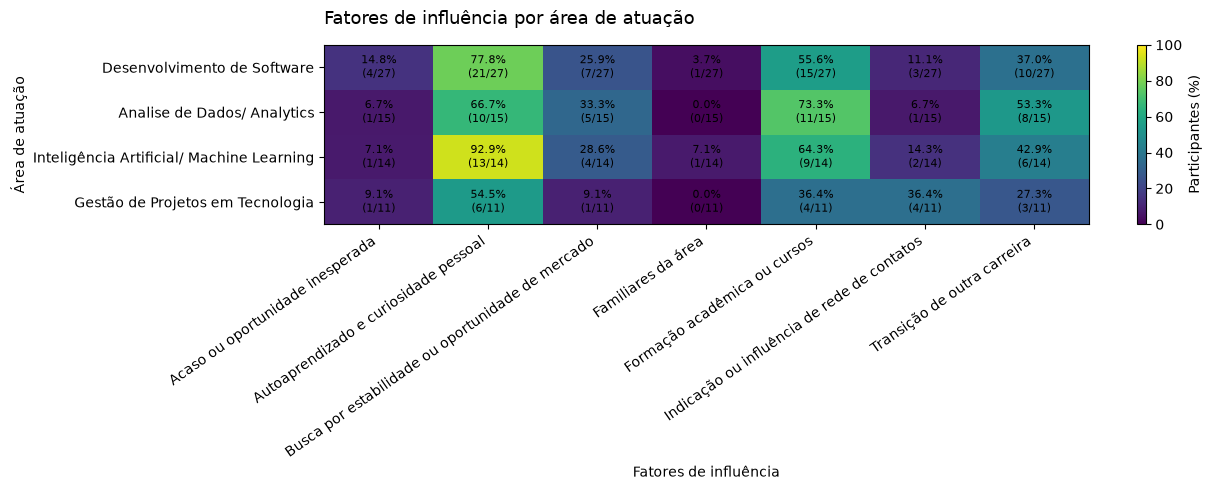

In [22]:
# Visualização — Fatores de influência por área de atuação

fig, ax = plt.subplots(figsize=(13, 5))

imagem = ax.imshow(percentual_area, aspect="auto", cmap="viridis", vmin=0, vmax=100)

ax.set_xticks(range(len(percentual_area.columns)))
ax.set_xticklabels(percentual_area.columns, rotation=35, ha="right")

ax.set_yticks(range(len(percentual_area.index)))
ax.set_yticklabels(percentual_area.index)

# Quantidade de participantes em cada área
total_por_area = participantes_area.set_index("area")["participantes"]

# Exibição do percentual e da quantidade de participantes
for i, area in enumerate(percentual_area.index):
    total = total_por_area.loc[area]

    for j, fator in enumerate(percentual_area.columns):
        percentual = percentual_area.loc[area, fator]
        quantidade = frequencia_area_filtrada.loc[area, fator]

        ax.text(
            j,
            i,
            f"{percentual:.1f}%\n({quantidade}/{total})",
            ha="center",
            va="center",
            fontsize=8,
        )

ax.set_title(
    "Fatores de influência por área de atuação", loc="left", fontsize=13, pad=15
)

ax.set_xlabel("Fatores de influência")
ax.set_ylabel("Área de atuação")

fig.colorbar(imagem, ax=ax, label="Participantes (%)")

plt.tight_layout()
plt.show()

### Leitura analítica

**Nota metodológica:** os participantes puderam indicar mais de uma área de atuação. Assim, aqueles que selecionaram múltiplas áreas são contabilizados em cada grupo correspondente. Por esse motivo, a soma dos participantes por área pode ultrapassar os 54 respondentes da pesquisa. Os percentuais são calculados dentro de cada grupo profissional.

O cruzamento evidencia diferenças na combinação dos fatores que influenciaram as trajetórias profissionais nas quatro áreas analisadas. Embora o autoaprendizado e a curiosidade pessoal apareçam com destaque em todos os grupos, a participação dos demais fatores varia conforme a área de atuação.

Em **Inteligência Artificial/Machine Learning**, destaca-se o autoaprendizado e a curiosidade pessoal, indicados por 92,9% dos participantes desse grupo (13 de 14). A formação acadêmica ou cursos também apresenta participação expressiva, com 64,3% (9 de 14). Os resultados mostram a presença simultânea da iniciativa individual e da formação estruturada entre os fatores assinalados.

Em **Análise de Dados/Analytics**, a formação acadêmica ou cursos alcança 73,3% (11 de 15), superando o percentual de autoaprendizado e curiosidade pessoal, de 66,7% (10 de 15). Também chama atenção a transição de outra carreira, indicada por 53,3% dos participantes (8 de 15), o maior percentual desse fator entre as quatro áreas. Esse resultado sugere uma presença expressiva de trajetórias de transição profissional nesse grupo.

Em **Desenvolvimento de Software**, o autoaprendizado e a curiosidade pessoal aparecem em 77,8% dos participantes (21 de 27), seguidos pela formação acadêmica ou cursos, com 55,6% (15 de 27). A transição de outra carreira foi indicada por 37,0% (10 de 27), enquanto a busca por estabilidade ou oportunidade de mercado aparece em 25,9% (7 de 27).

Já em **Gestão de Projetos em Tecnologia**, o autoaprendizado e a curiosidade pessoal também constituem o fator mais assinalado, com 54,5% (6 de 11). A indicação ou influência da rede de contatos aparece com 36,4% (4 de 11), mesmo percentual observado para a formação acadêmica ou cursos. Nesse grupo, a busca por estabilidade ou oportunidade de mercado foi indicada por 9,1% (1 de 11), o menor percentual entre as quatro áreas.

De maneira geral, os resultados apontam para diferentes combinações de influências nas trajetórias profissionais. O autoaprendizado e a curiosidade pessoal apresentam recorrência nas quatro áreas, enquanto a formação acadêmica, a transição de carreira e a influência das redes de contato assumem proporções distintas entre os grupos.

Essas diferenças reforçam que as trajetórias de entrada e desenvolvimento na tecnologia não seguem um percurso único. Os dados mostram a coexistência de iniciativas individuais, processos de formação e experiências profissionais anteriores, com diferentes configurações conforme a área de atuação. Como se trata de um cruzamento exploratório de uma amostra de 54 participantes, os resultados descrevem os grupos investigados e não permitem estabelecer relações causais ou generalizações para o conjunto dos profissionais de tecnologia.

 # 05 — Síntese analítica

Articulação dos resultados sobre os fatores que influenciaram as trajetórias profissionais, considerando as combinações de escolhas e os cruzamentos exploratórios realizados.



A análise da trajetória profissional dos participantes evidencia a presença de diferentes fatores de influência na aproximação e inserção na área de tecnologia. Entre os mais assinalados estão o **autoaprendizado e a curiosidade pessoal (70,4%)**, a **formação acadêmica ou cursos (63,0%)** e a **transição de outra carreira (40,7%)**.

A combinação desses fatores reforça que as trajetórias investigadas não seguem um percurso único. Embora 48,1% dos participantes tenham selecionado os três fatores permitidos pelo questionário, as combinações mais frequentes foram registradas por apenas seis participantes cada (11,1%). Isso evidencia a diversidade de articulações entre aprendizado autônomo, formação estruturada, transição profissional e oportunidades de mercado.

Os cruzamentos exploratórios acrescentam outras perspectivas. O aprendizado autônomo aparece em todas as faixas etárias e tempos de atuação, com percentuais elevados em diferentes grupos. A formação acadêmica também se mostra presente em distintas configurações profissionais. Já a transição de carreira apresenta variações entre os grupos, destacando-se entre participantes de faixas etárias mais elevadas e em algumas áreas de atuação.

Na comparação por área profissional, o autoaprendizado apresenta percentuais expressivos nas quatro áreas analisadas, enquanto a formação acadêmica ou cursos ganha destaque entre participantes de Análise de Dados/Analytics e Inteligência Artificial/Machine Learning. A transição de carreira também aparece de forma relevante, especialmente em Análise de Dados/Analytics.

Em conjunto, os resultados apontam para trajetórias construídas pela articulação entre iniciativa individual, formação e experiências profissionais anteriores. A entrada na tecnologia não se restringe a um caminho exclusivamente acadêmico ou a uma sequência linear de formação e emprego.

**Limite da análise:** os resultados representam as percepções dos 54 participantes da pesquisa. Como a questão permitia múltiplas escolhas e os cruzamentos envolvem grupos de tamanhos diferentes, os percentuais devem ser interpretados como evidências exploratórias da amostra, sem estabelecer relações causais ou generalizações para todo o setor.

# 06 — Encerramento do Eixo 2 — Jornada

### Delimitação do eixo

A análise deste eixo esteve restrita aos fatores de influência declarados pelos 54 participantes no questionário e às relações exploratórias observadas entre essas escolhas e suas características profissionais.

Os resultados expressam as percepções da amostra investigada e não permitem estabelecer relações causais ou generalizações para o conjunto dos profissionais de tecnologia.

### Continuidade da investigação

A pesquisa avança da investigação das trajetórias profissionais para outras dimensões da experiência dos participantes:

- **Eixo 3 — Realidade:** condições, percepções e experiências do cotidiano profissional.
- **Eixo 4 — Olhando para frente:** expectativas e perspectivas sobre as transformações futuras do trabalho em tecnologia.